In [4]:
import os
import shutil
import torch
import torchvision.transforms as transforms
from torchvision import models
from torch.utils.data import DataLoader, Dataset
from PIL import Image
from tqdm import tqdm
import torchxrayvision as xrv

# ---- Configuration ----
LABELED_DIR = r'F:\clustering\class_labeled'
UNLABELED_DIR = r'F:\clustering\unlabel'
SAVE_DIR = r'F:\clustering\label_o'
IMAGE_EXTENSIONS = ('.png', '.jpg', '.jpeg', '.bmp')
BATCH_SIZE = 32
CONFIDENCE_THRESHOLD = 0.80
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ---- Image Dataset ----
class ImageFolderWithPaths(Dataset):
    def __init__(self, root, transform=None, labeled=True):
        self.image_paths = []
        self.labels = []
        self.class_names = []
        self.transform = transform
        self.labeled = labeled
        self.class_to_idx = {}

        if labeled:
            subfolders = sorted([d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d))])
            self.class_names = subfolders
            self.class_to_idx = {cls_name: idx for idx, cls_name in enumerate(subfolders)}
            for cls_name in subfolders:
                cls_dir = os.path.join(root, cls_name)
                for fname in os.listdir(cls_dir):
                    if fname.lower().endswith(IMAGE_EXTENSIONS):
                        self.image_paths.append(os.path.join(cls_dir, fname))
                        self.labels.append(self.class_to_idx[cls_name])
        else:
            for fname in os.listdir(root):
                if fname.lower().endswith(IMAGE_EXTENSIONS):
                    self.image_paths.append(os.path.join(root, fname))

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        path = self.image_paths[idx]
        image = Image.open(path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        if self.labeled:
            return image, self.labels[idx], path
        else:
            return image, path

# ---- Transform ----
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(),
    transforms.ToTensor(),
    transforms.Lambda(lambda x: (x * 255.0 - 1024.0).clamp(-1024, 1024))
])


# ---- Feature Extractor ----
model = xrv.models.DenseNet(weights="all") 
model.eval().to(DEVICE)

def extract_features(dataloader, labeled=True):
    features = []
    info = []
    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Extracting features"):
            if labeled:
                images, labels, paths = batch
            else:
                images, paths = batch
            images = images.to(DEVICE)
            feats = model(images) 
            features.append(feats.cpu())
            info.extend(zip(paths, labels) if labeled else paths)
    return torch.cat(features), info


#  Extract Labeled Features and Compute Centroids ----
labeled_dataset = ImageFolderWithPaths(LABELED_DIR, transform, labeled=True)
labeled_loader = DataLoader(labeled_dataset, batch_size=BATCH_SIZE, shuffle=False)
labeled_features, labeled_info = extract_features(labeled_loader, labeled=True)

# Compute centroids per class
class_to_features = {}
for (path, label), feature in zip(labeled_info, labeled_features):
    class_name = labeled_dataset.class_names[label]
    class_to_features.setdefault(class_name, []).append(feature)

class_centroids = {}
for class_name, feats in class_to_features.items():
    class_centroids[class_name] = torch.stack(feats).mean(dim=0)

#  Extract Unlabeled Features and Assign to Nearest Class ----
unlabeled_dataset = ImageFolderWithPaths(UNLABELED_DIR, transform, labeled=False)
unlabeled_loader = DataLoader(unlabeled_dataset, batch_size=BATCH_SIZE, shuffle=False)
unlabeled_features, image_paths = extract_features(unlabeled_loader, labeled=False)

# Assign each unlabeled image to nearest centroid or "unknown"
assigned_labels = []
filtered_image_paths = []

unknown_paths = []

centroid_names = list(class_centroids.keys())
centroid_vectors = torch.stack([class_centroids[name] for name in centroid_names])
centroid_vectors_norm = torch.nn.functional.normalize(centroid_vectors, dim=1)

for feature, path in tqdm(zip(unlabeled_features, image_paths), total=len(unlabeled_features), desc="Clustering unlabeled"):
    feature_norm = torch.nn.functional.normalize(feature.unsqueeze(0), dim=1)
    similarities = torch.matmul(centroid_vectors_norm, feature_norm.squeeze())
    max_sim, nearest_idx = similarities.max(dim=0)

    if max_sim.item() >= CONFIDENCE_THRESHOLD:
        assigned_labels.append(centroid_names[nearest_idx])
        filtered_image_paths.append(path)
    else:
        unknown_paths.append(path)

from collections import defaultdict

# Track filenames and all classes they appear in
seen_filenames = defaultdict(set)  # {filename: set(class_names)}

# Create output directories
for class_name in centroid_names + ['unknown', 'overlap']:
    os.makedirs(os.path.join(SAVE_DIR, class_name), exist_ok=True)

#  Copy labeled images ----
for (path, label) in labeled_info:
    class_name = labeled_dataset.class_names[label]
    filename = os.path.basename(path)
    seen_filenames[filename].add(class_name)
    dst = os.path.join(SAVE_DIR, class_name, filename)
    shutil.copy2(path, dst)

# Copy confidently labeled unlabeled images ----
for path, class_name in zip(filtered_image_paths, assigned_labels):
    filename = os.path.basename(path)
    seen_filenames[filename].add(class_name)
    dst = os.path.join(SAVE_DIR, class_name, filename)
    shutil.copy2(path, dst)

#  Copy low-confidence to unknown ----
for path in unknown_paths:
    filename = os.path.basename(path)
    seen_filenames[filename].add('unknown')
    dst = os.path.join(SAVE_DIR, 'unknown', filename)
    shutil.copy2(path, dst)

# Remove all overlaps and move to 'overlap' folder ----
overlap_dir = os.path.join(SAVE_DIR, 'overlap')
overlap_count = 0

for filename, class_set in seen_filenames.items():
    if len(class_set) > 1:
        overlap_count += 1
        for class_name in class_set:
            file_path = os.path.join(SAVE_DIR, class_name, filename)
            if os.path.exists(file_path):
                os.remove(file_path)
        # Save only one copy to 'overlap'
        for class_name in class_set:
            src_path = os.path.join(SAVE_DIR, class_name, filename)
            orig_paths = labeled_dataset.image_paths + filtered_image_paths + unknown_paths
            for original_path in orig_paths:
                if os.path.basename(original_path) == filename:
                    shutil.copy2(original_path, os.path.join(overlap_dir, filename))
                    break
            break

# ---- Final Status ----
print(f"✅ Clustering complete.")
print(f"🧪 Assigned {len(assigned_labels)} / {len(unlabeled_features)} unlabeled images with ≥ {CONFIDENCE_THRESHOLD * 100:.0f}% confidence.")
print(f"🕳️ {len(unknown_paths)} images saved to 'unknown' due to low confidence.")
print(f"⚠️ {overlap_count} images found in more than one class and removed. Saved in 'overlap' folder.")
print("📁 Final output stored in:", SAVE_DIR)


Clustering unlabeled: 100%|██████████| 9372/9372 [00:00<00:00, 22904.15it/s]


✅ Clustering complete.
🧪 Assigned 9372 / 9372 unlabeled images with ≥ 80% confidence.
🕳️ 0 images saved to 'unknown' due to low confidence.
⚠️ 0 images found in more than one class and removed. Saved in 'overlap' folder.
📁 Final output stored in: F:\clustering\label_o



📉 Reducing features to 2D using t-SNE for visualization with contour boundaries...


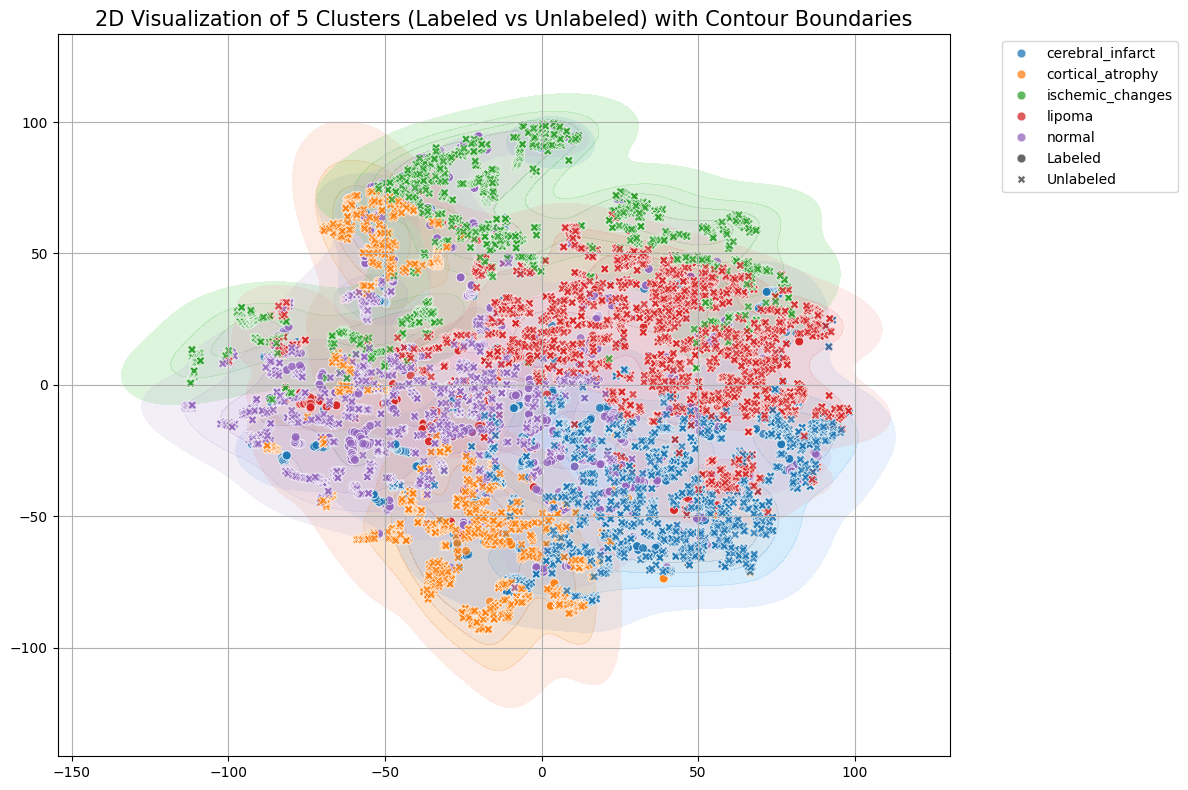

In [6]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("\n📉 Reducing features to 2D using t-SNE for visualization with contour boundaries...")

# Combine features + labels
all_features = []
all_cluster_labels = []
all_data_sources = []

# Labeled data
for (path, label), feature in zip(labeled_info, labeled_features):
    cluster_name = labeled_dataset.class_names[label]
    all_features.append(feature.numpy())
    all_cluster_labels.append(cluster_name)
    all_data_sources.append("Labeled")

# Unlabeled data
for feature, cluster_name in zip(unlabeled_features, assigned_labels):
    all_features.append(feature.numpy())
    all_cluster_labels.append(cluster_name)
    all_data_sources.append("Unlabeled")

# Run t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
features_2d = tsne.fit_transform(np.array(all_features))

# Convert to arrays for indexing
features_2d = np.array(features_2d)
all_cluster_labels = np.array(all_cluster_labels)
all_data_sources = np.array(all_data_sources)

# Set up plot
plt.figure(figsize=(12, 8))
ax = plt.gca()

# Plot contour per cluster
unique_clusters = sorted(np.unique(all_cluster_labels))
palette = sns.color_palette("tab10", n_colors=len(unique_clusters))
cluster_to_color = {cls: palette[i] for i, cls in enumerate(unique_clusters)}

for cls in unique_clusters:
    indices = np.where(all_cluster_labels == cls)[0]
    cls_points = features_2d[indices]
    
    # Plot KDE-based contour
    if len(cls_points) >= 10:  
        sns.kdeplot(
        x=cls_points[:, 0],
        y=cls_points[:, 1],
        ax=ax,
        fill=True,
        levels=5,  
        alpha=0.2,
        linewidths=1.5,
        color=cluster_to_color[cls],
        label=None
)

# Scatter points
sns.scatterplot(
    x=features_2d[:, 0],
    y=features_2d[:, 1],
    hue=all_cluster_labels,
    style=all_data_sources,
    palette=cluster_to_color,
    s=40,
    alpha=0.75,
    ax=ax
)

plt.title("2D Visualization of 5 Clusters (Labeled vs Unlabeled) with Contour Boundaries", fontsize=15)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()


